<a href="https://colab.research.google.com/github/yegnasai/DLAC-S12/blob/main/Copy_of_VisionPort_DL_Lifecycle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics opencv-python-headless pandas matplotlib

In [ ]:
import os
import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Video

print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

device = 0 if torch.cuda.is_available() else "cpu"
print("Selected device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV: 4.14.0
PyTorch: 2.14.1+cu130
GPU available: True
Selected device: 0


In [ ]:
uploaded = files.upload()

video_path = next(
    (name for name in uploaded if name.lower().endswith(
        (".mp4", ".avi", ".mov", ".mkv")
    )),
    None
)

if video_path is None:
    raise ValueError("Please upload a supported traffic video.")

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Unable to open the uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("Video:", video_path)
print("FPS:", fps)
print("Total Frames:", frame_count)
print("Resolution:", width, "x", height)

cap.release()


Saving traffic.mp4.mp4 to traffic.mp4.mp4
Video: traffic.mp4.mp4
FPS: 29.97002997002997
Total Frames: 464
Resolution: 1920 x 1080


In [ ]:
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")
print("Model: YOLO11 Nano")
print("Device:", device)

YOLO model loaded successfully!
Model: YOLO11 Nano
Device: 0


In [ ]:
import os

os.makedirs("extracted_frames", exist_ok=True)

cap = cv2.VideoCapture(video_path)

saved = 0
frame_number = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_number % 30 == 0:
        resized = cv2.resize(frame, (640, 360))

        cv2.imwrite(
            f"extracted_frames/frame_{saved}.jpg",
            resized
        )

        saved += 1

    frame_number += 1

cap.release()

print("Total frames processed:", frame_number)
print("Frames extracted:", saved)

Total frames processed: 464
Frames extracted: 16


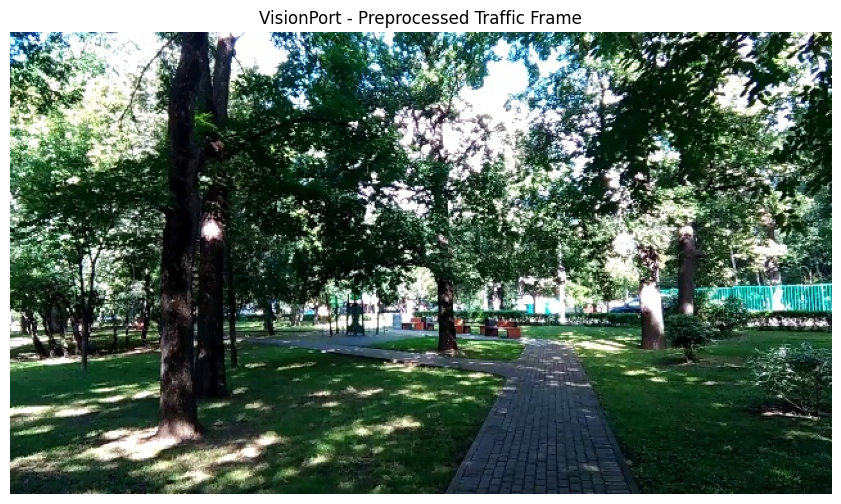

In [ ]:
image = cv2.imread("extracted_frames/frame_0.jpg")

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("VisionPort - Preprocessed Traffic Frame")
plt.axis("off")
plt.show()

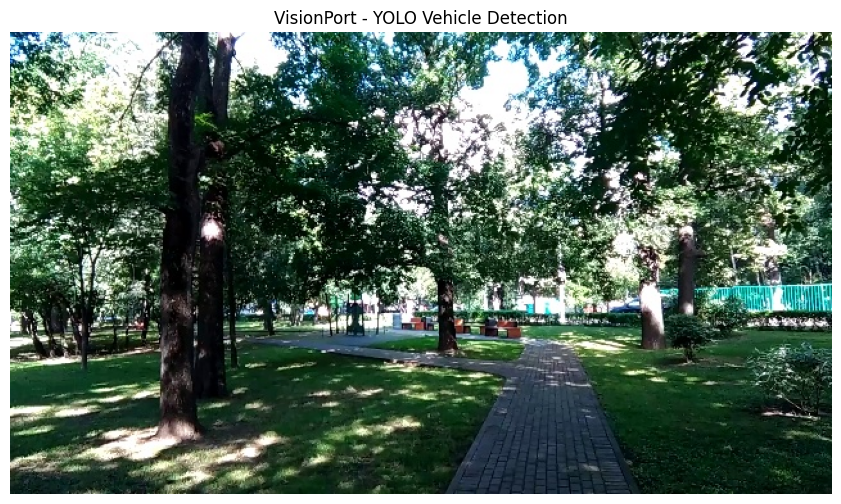

Vehicles detected: 0


In [ ]:
image = cv2.imread("extracted_frames/frame_0.jpg")

results = model.predict(
    image,
    classes=[2, 3, 5, 7],
    conf=0.25,
    device=device,
    verbose=False
)

annotated = results[0].plot()

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("VisionPort - YOLO Vehicle Detection")
plt.axis("off")
plt.show()

print("Vehicles detected:", len(results[0].boxes))

In [ ]:
cap = cv2.VideoCapture(video_path)

unique_vehicle_ids = set()
frame_results = []

frame_no = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        device=device,
        verbose=False
    )

    boxes = results[0].boxes
    detected = len(boxes)

    if boxes.id is not None:
        ids = boxes.id.int().cpu().tolist()
        unique_vehicle_ids.update(ids)

    frame_results.append({
        "Frame": frame_no,
        "Vehicles_Detected": detected
    })

    frame_no += 1

cap.release()

df = pd.DataFrame(frame_results)

print("Total frames:", frame_no)
print("Unique tracked IDs:", len(unique_vehicle_ids))
print("Maximum vehicles in a frame:", df["Vehicles_Detected"].max())

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 259ms
Prepared 1 package in 52ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Total frames: 464
Unique tracked IDs: 15
Maximum vehicles in a frame: 2


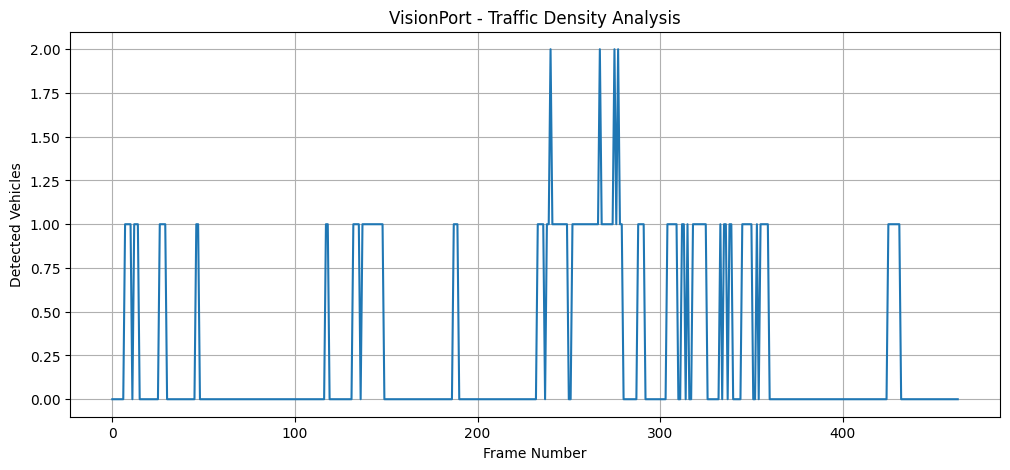

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Frame"],
    df["Vehicles_Detected"]
)

plt.title("VisionPort - Traffic Density Analysis")
plt.xlabel("Frame Number")
plt.ylabel("Detected Vehicles")
plt.grid(True)

plt.show()

In [ ]:
def classify_congestion(count):
    if count <= 3:
        return "LOW"
    elif count <= 7:
        return "MEDIUM"
    else:
        return "HIGH"

df["Congestion_Level"] = df[
    "Vehicles_Detected"
].apply(classify_congestion)

print(df["Congestion_Level"].value_counts())

display(df.head(10))

Congestion_Level
LOW    464
Name: count, dtype: int64


,Frame,Vehicles_Detected,Congestion_Level
0,0,0,LOW
1,1,0,LOW
2,2,0,LOW
3,3,0,LOW
4,4,0,LOW
5,5,0,LOW
6,6,0,LOW
7,7,1,LOW
8,8,1,LOW
9,9,1,LOW


In [ ]:
summary = pd.DataFrame({
    "Metric": [
        "Total Frames",
        "Maximum Vehicles per Frame",
        "Average Vehicles per Frame",
        "Unique Tracking IDs",
        "High Congestion Frames"
    ],
    "Value": [
        len(df),
        df["Vehicles_Detected"].max(),
        round(df["Vehicles_Detected"].mean(), 2),
        len(unique_vehicle_ids),
        (df["Congestion_Level"] == "HIGH").sum()
    ]
})

display(summary)

df.to_csv("visionport_traffic_analysis.csv", index=False)
summary.to_csv("visionport_summary.csv", index=False)

print("Results exported successfully!")

,Metric,Value
0,Total Frames,464.00
1,Maximum Vehicles per Frame,2.00
2,Average Vehicles per Frame,0.27
3,Unique Tracking IDs,15.00
4,High Congestion Frames,0.00


Results exported successfully!


In [ ]:
lifecycle = pd.DataFrame({
    "DL Lifecycle Stage": [
        "Problem Definition",
        "Data Collection",
        "Data Preprocessing",
        "Model Selection",
        "Model Training",
        "Model Inference",
        "Model Evaluation",
        "Deployment",
        "Monitoring"
    ],
    "VisionPort Implementation": [
        "Automated traffic monitoring",
        "Uploaded road traffic video",
        "OpenCV frame extraction and resizing",
        "Pretrained YOLO11 Nano",
        "Pretrained model; no custom training",
        "YOLO vehicle detection",
        "Functional statistics; formal accuracy pending",
        "Execution in Google Colab",
        "Traffic counts and congestion classification"
    ]
})

display(lifecycle)

lifecycle.to_csv(
    "VisionPort_DL_Lifecycle_Mapping.csv",
    index=False
)

,DL Lifecycle Stage,VisionPort Implementation
0,Problem Definition,Automated traffic monitoring
1,Data Collection,Uploaded road traffic video
2,Data Preprocessing,OpenCV frame extraction and resizing
3,Model Selection,Pretrained YOLO11 Nano
4,Model Training,Pretrained model; no custom training
5,Model Inference,YOLO vehicle detection
6,Model Evaluation,Functional statistics; formal accuracy pending
7,Deployment,Execution in Google Colab
8,Monitoring,Traffic counts and congestion classification
